# Verify Yaw Randomization in Arena Forage

Initialize the arena forage environment with 5 different RNG seeds and render
the initial frame from a top-down camera to confirm the rodent spawns at
different yaw angles.

In [1]:
import os

os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import jax
import jax.numpy as jp
import mujoco
import numpy as np
import matplotlib.pyplot as plt

from scamper.environment.rodent import arena_forage
from scamper.environment.rodent import consts as rodent_consts

In [2]:
cfg = arena_forage.default_config()
cfg.num_treats = 5
cfg.spawn_radius = 1.5
cfg.min_spawn_radius = 0.5
cfg.mujoco_impl = "warp"

env = arena_forage.ArenaForage(config=cfg)
print(f"Action size: {env.action_size}")
print(f"Observation size: {env.observation_size}")

Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA L40S" (45 GiB, sm_89, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Action size: 38
Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 17.84 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 4.94 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 5.22 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_38dc074a a18cc1c load on device 'cuda:0' took 1259.36 ms  (compiled)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd

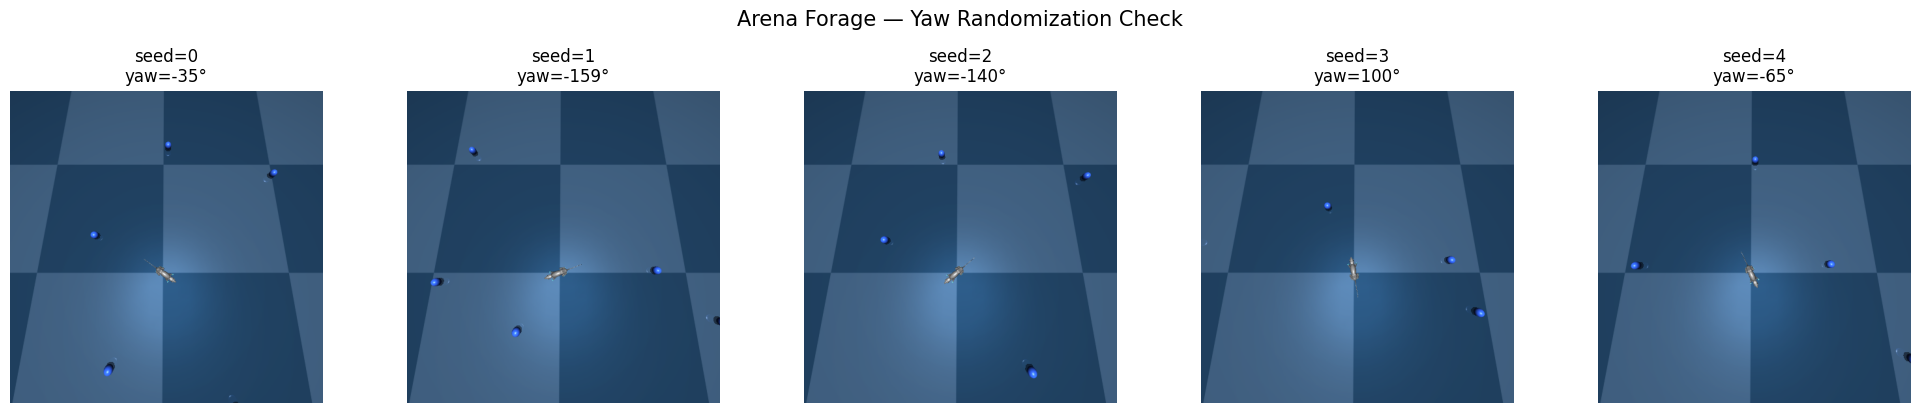

In [4]:
jit_reset = jax.jit(env.reset)

seeds = [0, 1, 2, 3, 4]
height, width = 480, 480

mj_model = env.mj_model
mj_model.vis.global_.offwidth = width
mj_model.vis.global_.offheight = height
mj_data = mujoco.MjData(mj_model)
renderer = mujoco.Renderer(mj_model, height=height, width=width)

fig, axes = plt.subplots(1, len(seeds), figsize=(4 * len(seeds), 4))

for ax, seed in zip(axes, seeds):
    state = jit_reset(jax.random.PRNGKey(seed))
    qpos = np.array(state.data.qpos)
    qvel = np.array(state.data.qvel)

    # Extract yaw from quaternion for display
    w, x, y, z = qpos[3], qpos[4], qpos[5], qpos[6]
    yaw_rad = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y**2 + z**2))
    yaw_deg = np.degrees(yaw_rad)

    # Set up treat geom positions for rendering
    treat_positions = np.array(state.info["treat_positions"])
    num_treats = cfg.num_treats
    for i in range(num_treats):
        geom_id = mujoco.mj_name2id(mj_model, mujoco.mjtObj.mjOBJ_GEOM, f"treat_{i}")
        mj_model.geom_pos[geom_id] = treat_positions[i]

    mj_data.qpos[:] = qpos
    mj_data.qvel[:] = qvel
    mujoco.mj_forward(mj_model, mj_data)

    # Render top-down view
    renderer.update_scene(mj_data, camera="top-rodent")
    frame = renderer.render()

    ax.imshow(frame)
    ax.set_title(f"seed={seed}\nyaw={yaw_deg:.0f}°", fontsize=12)
    ax.axis("off")

plt.suptitle("Arena Forage — Yaw Randomization Check", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Print quaternions and yaw angles for verification
for seed in seeds:
    state = jit_reset(jax.random.PRNGKey(seed))
    qpos = np.array(state.data.qpos)
    quat = qpos[3:7]
    w, x, y, z = quat
    yaw_rad = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y**2 + z**2))
    print(
        f"seed={seed}: quat=[{w:.3f}, {x:.3f}, {y:.3f}, {z:.3f}]  yaw={np.degrees(yaw_rad):.1f}°"
    )